# Phân loại cảm xúc văn bản tiếng Việt — UIT-VSMEC
**Bài tập lớn Xử lý ngôn ngữ tự nhiên**

Pipeline: *dữ liệu thô → khảo sát/tiền xử lý → biểu diễn (TF-IDF / embedding) → mô hình (baseline tuyến tính vs. BiLSTM) → đánh giá (macro-F1) → phân tích lỗi.*

- **Đầu vào:** 1 câu bình luận tiếng Việt (mạng xã hội).
- **Đầu ra:** 1 trong 7 nhãn: Enjoyment, Sadness, Anger, Fear, Disgust, Surprise, Other.
- **Thước đo chính:** macro-F1 (dữ liệu mất cân bằng), kèm accuracy, weighted-F1, precision/recall từng lớp.
- **Quy tắc:** mọi lựa chọn dựa trên tập **valid**; tập **test** chỉ dùng để báo cáo cuối.

Mã nguồn chi tiết nằm trong thư mục `src/`; notebook này gọi lại các hàm đó và hiển thị kết quả.

## 0. Cài đặt môi trường
Trên Google Colab: bỏ comment 3 dòng đầu của cell dưới để tải mã nguồn và cài thư viện ([mở notebook bằng Colab](https://colab.research.google.com/github/quaneluscore123/NLP_ClassificationEmotions/blob/quan/notebooks/NLP_BTL_UIT_VSMEC.ipynb)).

In [1]:
# !git clone https://github.com/quaneluscore123/NLP_ClassificationEmotions.git
# %cd NLP_ClassificationEmotions
# !pip install -q -r requirements.txt
import os, sys, json
from pathlib import Path
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
import pandas as pd, numpy as np
from IPython.display import Image, display
pd.set_option("display.max_colwidth", 120); pd.set_option("display.width", 200)
print("Thư mục dự án:", ROOT)

Thư mục dự án: D:\NLP_ClassificationEmotions


## 1. Dữ liệu
**Nguồn:** UIT-VSMEC (Ho et al., 2019) — 6.927 câu bình luận Facebook tiếng Việt, gán nhãn thủ công 7 cảm xúc.
Dùng bản phân phối công khai trên Hugging Face (`tridm/UIT-VSMEC`), giữ nguyên split train/valid/test của tác giả.

In [2]:
from src.config import LABELS, TEXT_COL, LABEL_COL
from src.data import load_raw, clean_splits
raw = load_raw()
splits, clean_log = clean_splits(raw)
print(clean_log)
splits["train"].sample(8, random_state=1)

{'train_empty_removed': 0, 'valid_empty_removed': 0, 'test_empty_removed': 0, 'train_exact_dup_removed': 3, 'train_conflicting_label_removed': 1, 'valid_overlap_with_train': 1, 'test_overlap_with_train': 0}


,Sentence,Emotion
1410,cưng xỉu ~~??,Enjoyment
136,thằng cha bảo vệ có tâm quá . nge con nhỏ kêu nguyên đêm zi mà đéo cứu,Disgust
1576,"sao mày không viết nhanh lên , mày lấy tay chặn làm gì có giúp mày tốt hơn không hả ???",Anger
3536,con bé cưng gì đâu . vk ơi anh muốn có cục bảo bối như vậy per,Enjoyment
2472,lòng đường không phải nhà cụ nên cụ sai nhé . vỉa hè to vậy rồi cụ còn muốn như thế nào,Anger
169,hên là chay ra kip,Enjoyment
4239,hơn cả bộ phim kinh dị !,Fear
645,giọng chú hơi bị dễ thương nhá :)),Enjoyment


### 1.1 Thống kê (EDA)

In [3]:
from src.eda import run_eda
eda = run_eda(splits, clean_log)
display(eda["split_stats"])
display(eda["label_distribution"])

,split,n_sentences,n_tokens(syllable),vocab_size(syllable),mean_len,median_len,p95_len,max_len,dup_text,has_emoji,has_emoticon,broken_diacritic,has_per_token
0,train,5544,77656,4642,14.01,12.0,33.0,164,0,957,868,37,520
1,valid,686,9725,1903,14.18,12.0,31.0,80,0,114,102,6,51
2,test,693,9571,1850,13.81,11.0,31.0,64,1,132,107,4,60


,train,valid,test,train_%,valid_%,test_%
Emotion,,,,,,
Enjoyment,1558,214,193,28.10,31.20,27.85
Sadness,947,86,116,17.08,12.54,16.74
Anger,391,49,40,7.05,7.14,5.77
Fear,316,31,46,5.70,4.52,6.64
Disgust,1070,135,132,19.30,19.68,19.05
Surprise,242,30,37,4.37,4.37,5.34
Other,1020,141,129,18.40,20.55,18.61


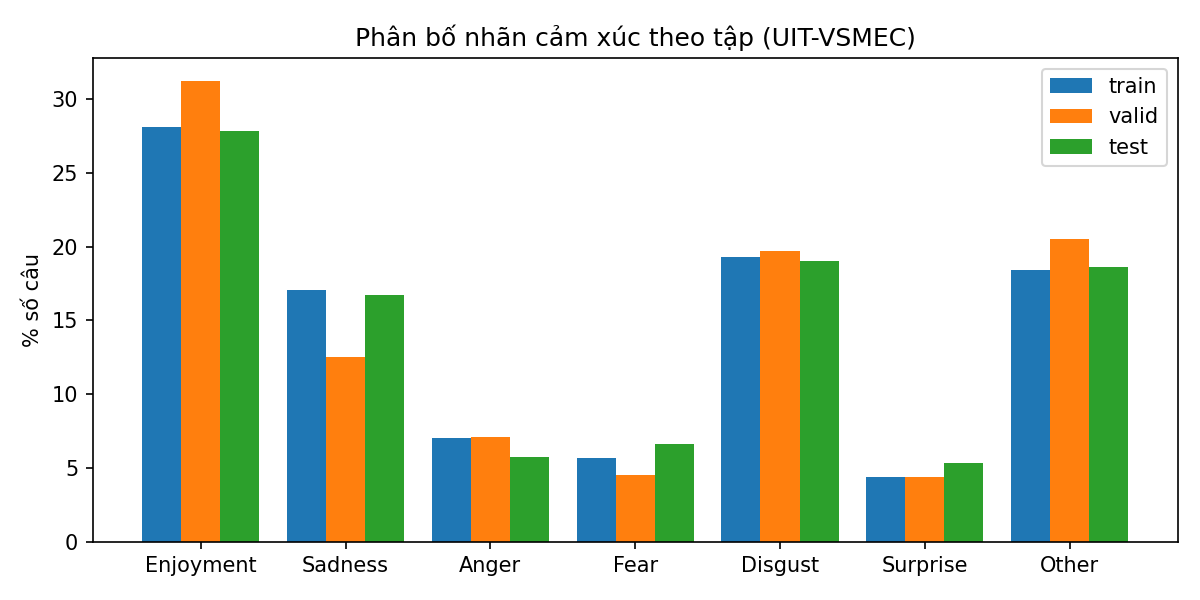

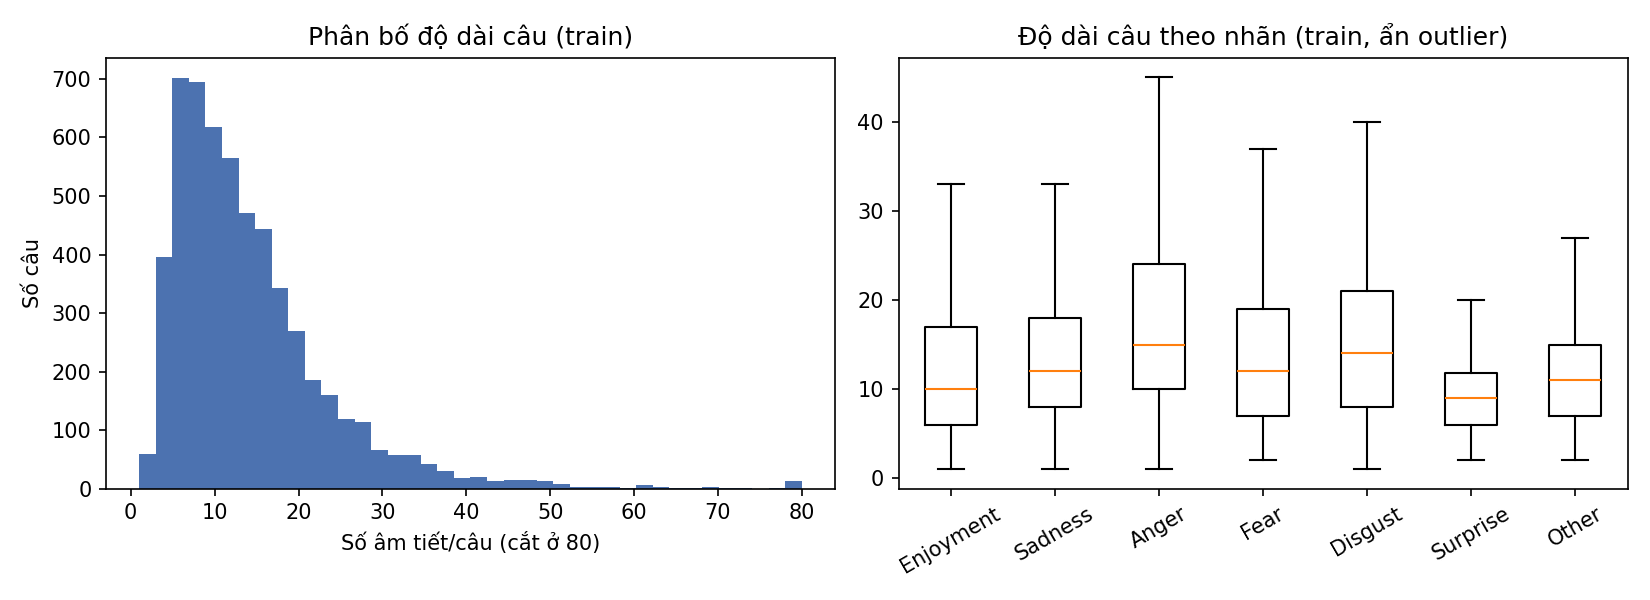

,count,mean,std,min,25%,50%,75%,max
Emotion,,,,,,,,
Enjoyment,1558.0,12.55,8.61,1.0,6.0,10.0,17.00,97.0
Sadness,947.0,13.98,8.37,1.0,8.0,12.0,18.00,54.0
Anger,391.0,18.34,12.61,1.0,10.0,15.0,24.00,87.0
Fear,316.0,14.96,11.39,2.0,7.0,12.0,19.00,81.0
Disgust,1070.0,17.10,14.92,1.0,8.0,14.0,21.00,164.0
Surprise,242.0,9.29,4.39,2.0,6.0,9.0,11.75,24.0
Other,1020.0,12.18,6.78,2.0,7.0,11.0,15.00,77.0


,label,n_sent_with_emoji,top_emoji
0,Enjoyment,372,😂(208) 🤣(126) ❤(36) 😍(35) 😊(31) 😆(28)
1,Sadness,194,😭(91) 😢(40) 😞(26) 😔(22) 😌(18) 😂(10)
2,Anger,53,🙂(17) 😡(16) 😭(14) 😒(12) 😠(9) 😂(5)
3,Fear,64,😭(15) 😂(11) 😢(11) 😨(10) 😱(7) 😅(7)
4,Disgust,135,😂(33) 🙂(20) 😑(19) 😌(19) 🤣(18) 😒(13)
5,Surprise,26,😂(9) 🤣(7) 😑(5) 😁(4) 🥰(3) 😱(3)
6,Other,113,😂(54) 🤣(15) 😌(12) 🙂(11) 🤔(9) 😍(6)


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
token,không,tao,là,có,mà,này,nó,đi,thì,người,con,rồi,cái,cho,per,được,cũng,gì,như,làm
count,1127,1052,1006,1002,846,727,717,683,665,660,643,610,573,551,536,522,486,472,472,446


In [4]:
display(Image("results/figures/eda_label_distribution.png"))
display(Image("results/figures/eda_length.png"))
display(eda["length_by_label"]); display(eda["emoji_by_label"]); display(eda["top_tokens"].head(20).T)

**Nhận xét:** dữ liệu mất cân bằng (Enjoyment ~28% so với Surprise ~4%) → dùng **macro-F1** làm thước đo chính và thử `class_weight`.
Câu ngắn (trung vị 12 âm tiết), nhiều emoji/emoticon, teencode, từ tục; token `per` là tên người đã được ẩn danh; một số câu lỗi dấu tổ hợp bị tách rời.

## 2. Tiền xử lý
Mỗi bước là một cờ để làm khảo sát có kiểm soát (ablation). Các bước đều là **quy tắc cố định** (không học tham số) nên không gây rò rỉ dữ liệu.

| Cấu hình | Mô tả |
|---|---|
| P0_raw | chỉ chữ thường |
| P1_normalize | + chuẩn Unicode NFC, sửa dấu tách rời, số→`num`, tách dấu câu, rút gọn ký tự lặp, emoticon→token (`:))`→`emo_cuoi`), emoji thành token riêng |
| P2_+teencode | + chuẩn hóa teencode (`ko`→`không`, `dc`→`được`...) |
| P3_+segment | + tách từ tiếng Việt (pyvi: `nước mắt`→`nước_mắt`) |
| P4_+stopwords | + loại hư từ (giữ phủ định / từ mức độ) |
| P5_-emoji/emoticon | như P3 nhưng xóa emoji & emoticon (kiểm tra vai trò của chúng) |

In [5]:
from src.preprocess import CONFIGS, preprocess
s = "t cu ̃ người cu ̀ người nghê ̀. ko biết đc gì :)))) 😡😡 xem tới đây ứa nước mắt"
for name, cfg in CONFIGS.items():
    print(f"{name:20s} -> {preprocess(s, cfg)}")
pd.read_csv("results/tables/preprocess_examples.csv", index_col=0)

P0_raw               -> t cu ̃ người cu ̀ người nghê ̀. ko biết đc gì :)))) 😡 😡 xem tới đây ứa nước mắt
P1_normalize         -> t cũ người cù người nghề . ko biết đc gì emo_cuoi 😡 😡 xem tới đây ứa nước mắt
P2_+teencode         -> tao cũ người cù người nghề . không biết được gì emo_cuoi 😡 😡 xem tới đây ứa nước mắt


P3_+segment          -> tao cũ người cù người nghề . không biết được gì emo_cuoi 😡 😡 xem tới đây ứa nước_mắt
P4_+stopwords        -> tao cũ người cù người nghề không biết gì emo_cuoi 😡 😡 xem tới đây ứa nước_mắt
P5_-emoji/emoticon   -> tao cũ người cù người nghề . không biết được gì xem tới đây ứa nước_mắt


,original,P0_raw,P1_normalize,P2_+teencode,P3_+segment,P4_+stopwords,P5_-emoji/emoticon
idx,,,,,,,
3,uớc gì sau này về già vẫn có thể như cụ này :)),uớc gì sau này về già vẫn có thể như cụ này :)),uớc gì sau này về già vẫn có thể như cụ này emo_cuoi,uớc gì sau này về già vẫn có thể như cụ này emo_cuoi,uớc gì sau_này về già vẫn có_thể như cụ này emo_cuoi,uớc gì sau_này về già vẫn có_thể cụ emo_cuoi,uớc gì sau_này về già vẫn có_thể như cụ này
7,thật hay đùa ác vậy . không thể tin được,thật hay đùa ác vậy . không thể tin được,thật hay đùa ác vậy . không thể tin được,thật hay đùa ác vậy . không thể tin được,thật hay đùa ác_vậy . không_thể tin được,thật hay đùa ác_vậy không_thể tin,thật hay đùa ác_vậy . không_thể tin được
15,"tui thi ́ ch va ̉ i lă ́ mày ma ̀ ăn nhỉ ̀ u no ́ người lă ́ mày mọi người anh ̣ , bi ̣ lơ ̉ miê ̣ người","tui thi ́ ch va ̉ i lă ́ mày ma ̀ ăn nhỉ ̀ u no ́ người lă ́ mày mọi người anh ̣ , bi ̣ lơ ̉ miê ̣ người","tui thí ch vả i lắ mày mà ăn nhỉ ̀ u nó người lắ mày mọi người anḥ , bị lở miệ người","tôi thí ch vả i lắ mày mà ăn nhỉ ̀ u nó người lắ mày mọi người anḥ , bị lở miệ người","tôi thí ch vả i lắ mày mà ăn nhỉ ̀ u nó người lắ mày mọi người anḥ , bị lở miệ người",tôi thí ch vả i lắ mày ăn nhỉ ̀ u nó người lắ mày mọi người anḥ lở miệ người,"tôi thí ch vả i lắ mày mà ăn nhỉ ̀ u nó người lắ mày mọi người anḥ , bị lở miệ người"
42,bản thân cố gắng cũng chẳng dễ dàng gì :((,bản thân cố gắng cũng chẳng dễ dàng gì :((,bản thân cố gắng cũng chẳng dễ dàng gì emo_buon,bản thân cố gắng cũng chẳng dễ dàng gì emo_buon,bản_thân cố_gắng cũng chẳng dễ_dàng gì emo_buon,bản_thân cố_gắng chẳng dễ_dàng gì emo_buon,bản_thân cố_gắng cũng chẳng dễ_dàng gì
100,nhận nhầm con cặc . phải nói là 10 thằng thì 1 thằng nuôi con thằng khác,nhận nhầm con cặc . phải nói là 10 thằng thì 1 thằng nuôi con thằng khác,nhận nhầm con cặc . phải nói là num thằng thì num thằng nuôi con thằng khác,nhận nhầm con cặc . phải nói là num thằng thì num thằng nuôi con thằng khác,nhận nhầm con cặc . phải nói là num thằng thì num thằng nuôi con thằng khác,nhận nhầm cặc phải nói num thằng num thằng nuôi thằng khác,nhận nhầm con cặc . phải nói là num thằng thì num thằng nuôi con thằng khác
2021,em chờ được mà 🙂,em chờ được mà 🙂,em chờ được mà 🙂,em chờ được mà 🙂,em chờ được mà 🙂,em chờ 🙂,em chờ được mà


## 3. Chạy toàn bộ thực nghiệm
`run_all.py` thực hiện: khảo sát tiền xử lý → khảo sát đặc trưng n-gram → grid-search siêu tham số baseline (trên valid) →
huấn luyện 6 biến thể RNN × 3 seed → đánh giá test → bootstrap → phân tích lỗi → lưu mô hình.

Mất khoảng 25–30 phút trên CPU. Đặt `RUN_FULL = False` để chỉ đọc lại kết quả đã lưu trong `results/`.

In [6]:
RUN_FULL = False
if RUN_FULL or not Path("results/summary.json").exists():
    import run_all
    run_all.main(fast=False)
summary = json.loads(Path("results/summary.json").read_text(encoding="utf-8"))
print(json.dumps({k: summary[k] for k in ["best_preprocess", "baseline_selection", "best_rnn", "seeds", "runtime_min"]},
                 indent=2, ensure_ascii=False))

{
  "best_preprocess": "P2_+teencode",
  "baseline_selection": {
    "MultinomialNB": {
      "feature": "word_1-2+char_2-5",
      "hp": {
        "alpha": 0.01
      },
      "val_macro_f1": 0.5402663596902434
    },
    "LogReg": {
      "feature": "word_1-2",
      "hp": {
        "C": 20,
        "class_weight": "balanced"
      },
      "val_macro_f1": 0.569290642058943
    },
    "LinearSVC": {
      "feature": "word_1-2+char_2-5",
      "hp": {
        "C": 1.0,
        "class_weight": "balanced"
      },
      "val_macro_f1": 0.5619108292193005
    }
  },
  "best_rnn": "R6_BiLSTM_maxmean_emb256",
  "seeds": [
    42,
    43,
    44
  ],
  "runtime_min": 27.4
}


## 4. Phương pháp 1 — Baseline TF-IDF + mô hình tuyến tính
### 4.1 Khảo sát tiền xử lý (TF-IDF word 1–2gram, macro-F1 trên valid)

model,LogReg,MultinomialNB
preprocess,,
P0_raw,0.5681,0.4739
P1_normalize,0.5639,0.4627
P2_+teencode,0.5693,0.4730
P3_+segment,0.5500,0.4707
P4_+stopwords,0.5286,0.4667
P5_-emoji/emoticon,0.5191,0.4417


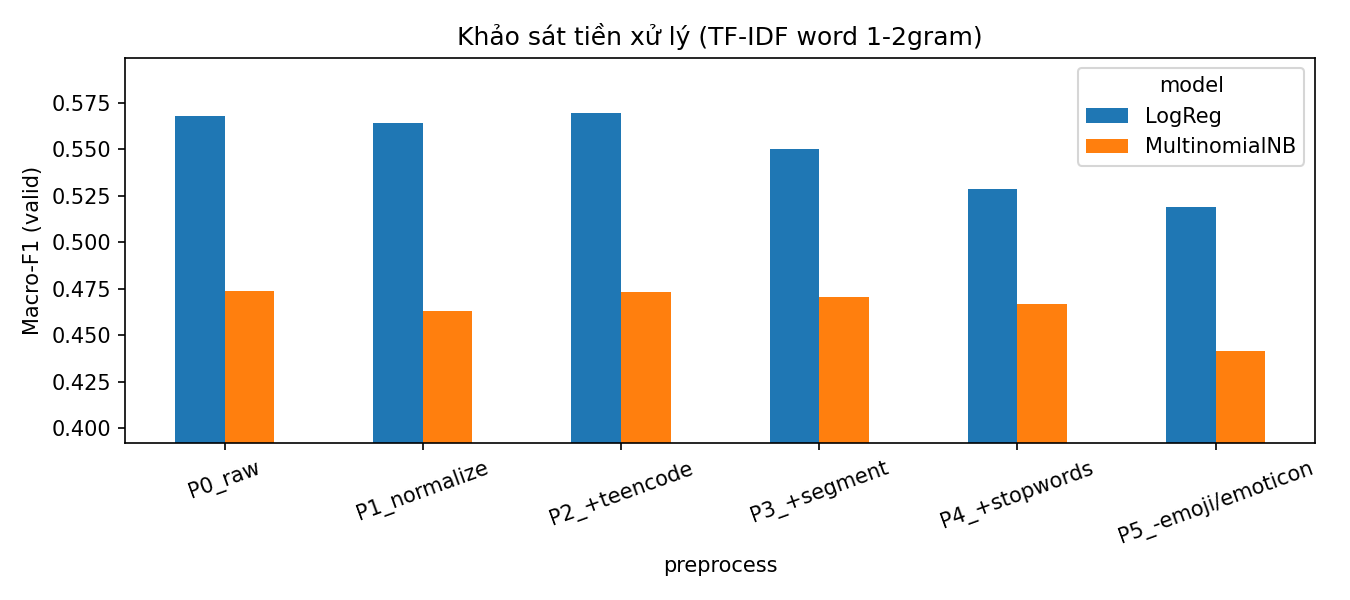

In [7]:
t = pd.read_csv("results/tables/ablation_preprocessing.csv")
display(t.pivot(index="preprocess", columns="model", values="val_macro_f1").reindex(list(CONFIGS)).round(4))
display(Image("results/figures/ablation_preprocessing.png"))

### 4.2 Khảo sát đặc trưng n-gram và mô hình

model,LinearSVC,LogReg,MultinomialNB
feature,,,
char_2-5,0.5252,0.5313,0.5223
word_1-1,0.5379,0.5253,0.4455
word_1-2,0.5576,0.5693,0.4730
word_1-2+char_2-5,0.5619,0.5619,0.5403
word_1-3,0.5551,0.5637,0.4829


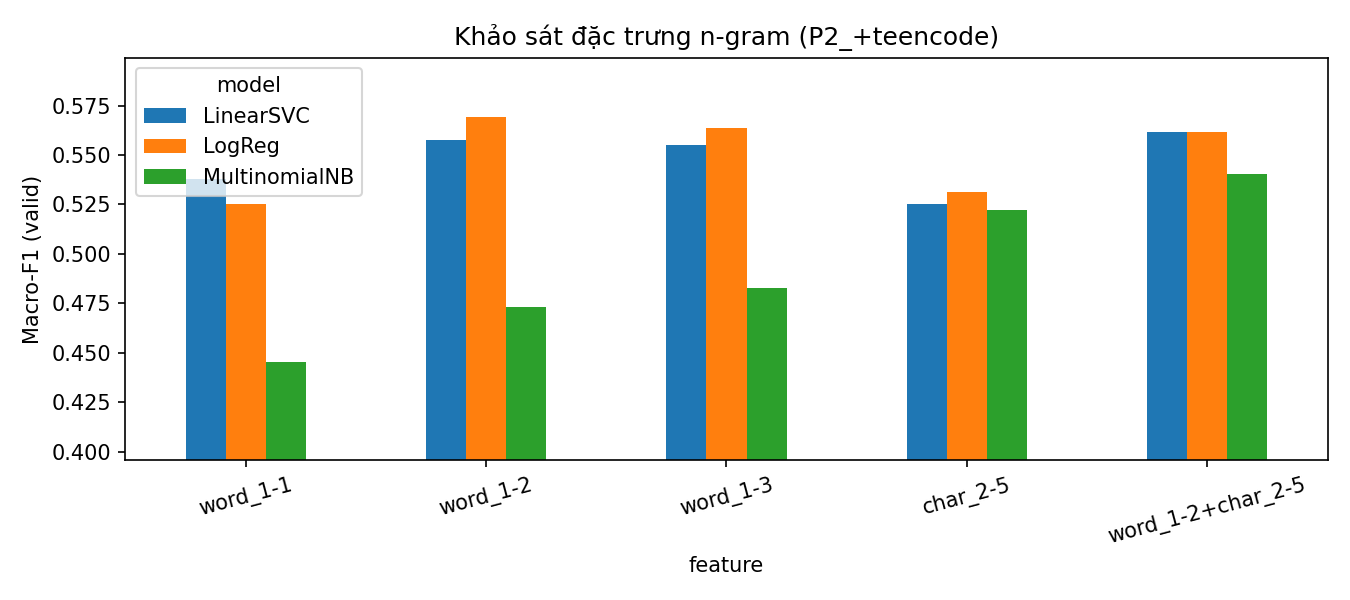

,label,top_features
0,Anger,"đéo, lol, mẹ, lồn, dume, mày, chết, tù, bọn, imm, khốn, chó"
1,Disgust,"ngu, nhạt, ghét, tởm, văn, gớm, hãm, kém, đéo, ác, thằng, bẩn"
2,Enjoyment,"cười, emo_cuoi, kk, cưng, haha, yêu, vui, 😂, 🤣, ❤, dễ, hay"
3,Fear,"sợ, hồn, nguy, hiểm, dám, chạy, nguy hiểm, chắc, ám ảnh, ám, xuống, thôi xong"
4,Other,"nên, thôi, hỏi, thay, nhiều, cái gì, bếp, đâu, nhé, sớm, vị, gì vậy"
5,Sadness,"emo_buon, buồn, huhu, tội, khổ, đau, 😢, tiếc, khóc, 😭, 😞, thương"
6,Surprise,"à, sao, ngờ, vậy, này, ?, wow, nhanh, đẹp, hả, giỏi, dữ"


In [8]:
t = pd.read_csv("results/tables/ablation_features.csv")
display(t.pivot(index="feature", columns="model", values="val_macro_f1").round(4))
display(Image("results/figures/ablation_features.png"))
display(pd.read_csv("results/tables/logreg_top_features.csv"))

Ví dụ huấn luyện nhanh baseline ngay trong notebook (cùng hàm với `run_all.py`):

In [9]:
from src import baseline as B
from src.evaluate import metrics
from src.preprocess import preprocess_series
cfg = CONFIGS[summary["best_preprocess"]]
X = {k: preprocess_series(v[TEXT_COL], cfg) for k, v in splits.items()}
y = {k: v[LABEL_COL].tolist() for k, v in splits.items()}
sel = summary["baseline_selection"]["LogReg"]
pipe = B.build_pipeline("LogReg", sel["feature"], **sel["hp"]).fit(X["train"], y["train"])  # vectorizer fit trên train
print("Cấu hình:", sel)
print("valid:", {k: round(v, 4) for k, v in metrics(y["valid"], pipe.predict(X["valid"])).items()})

Cấu hình: {'feature': 'word_1-2', 'hp': {'C': 20, 'class_weight': 'balanced'}, 'val_macro_f1': 0.569290642058943}
valid: {'macro_f1': 0.5693, 'macro_precision': 0.572, 'macro_recall': 0.5747, 'weighted_f1': 0.6016, 'accuracy': 0.602}


## 5. Phương pháp 2 — (Bi)LSTM với TensorFlow/Keras
Kiến trúc: `TextVectorization (adapt trên train)` → `Embedding(mask_zero)` → `SpatialDropout` → `BiLSTM` → (pooling) → `Dense(64)` → `Softmax(7)`.
Early stopping theo **macro-F1 valid**, khôi phục trọng số tốt nhất; `class_weight="balanced"`; mỗi cấu hình chạy 3 seed.

,variant,preprocess,bidirectional,emb_dim,class_weight,val_macro_f1_mean,val_macro_f1_std,best_epoch_mean,n_params,train_sec_mean
0,R1_LSTM_last,P2_+teencode,False,128,True,0.4863,0.0099,12.3333,592391,64.5000
1,R2_BiLSTM_last,P2_+teencode,True,128,True,0.4967,0.0073,9.6667,645895,67.5000
2,R3_BiLSTM_maxmean,P2_+teencode,True,128,True,0.5029,0.0085,9.3333,654087,74.4333
3,R4_BiLSTM_maxmean_segment,P3_+segment,True,128,True,0.4780,0.0189,5.0000,919943,48.6667
4,R5_BiLSTM_maxmean_noCW,P2_+teencode,True,128,False,0.4840,0.0050,7.6667,654087,56.2333
5,R6_BiLSTM_maxmean_emb256,P2_+teencode,True,256,True,0.5077,0.0183,8.6667,1257991,71.9333


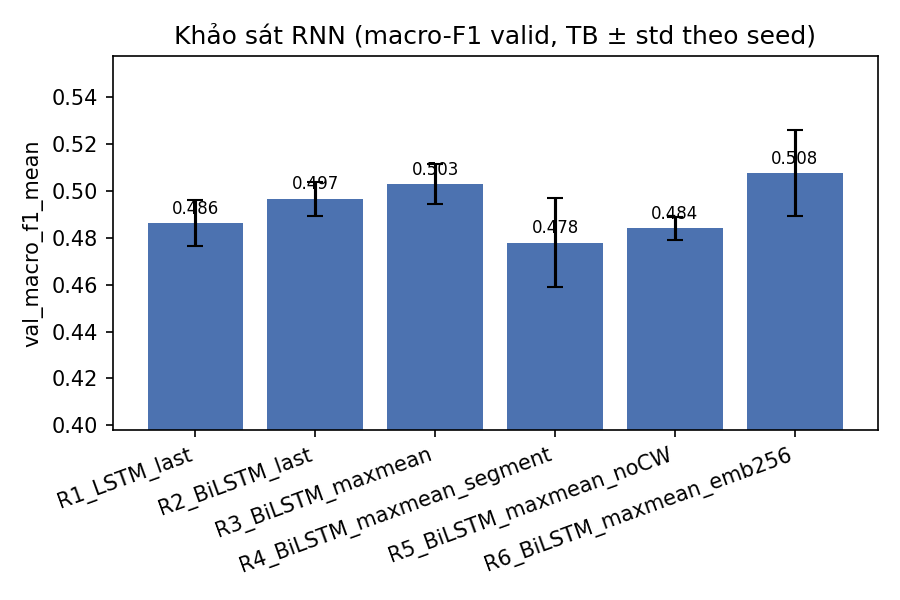

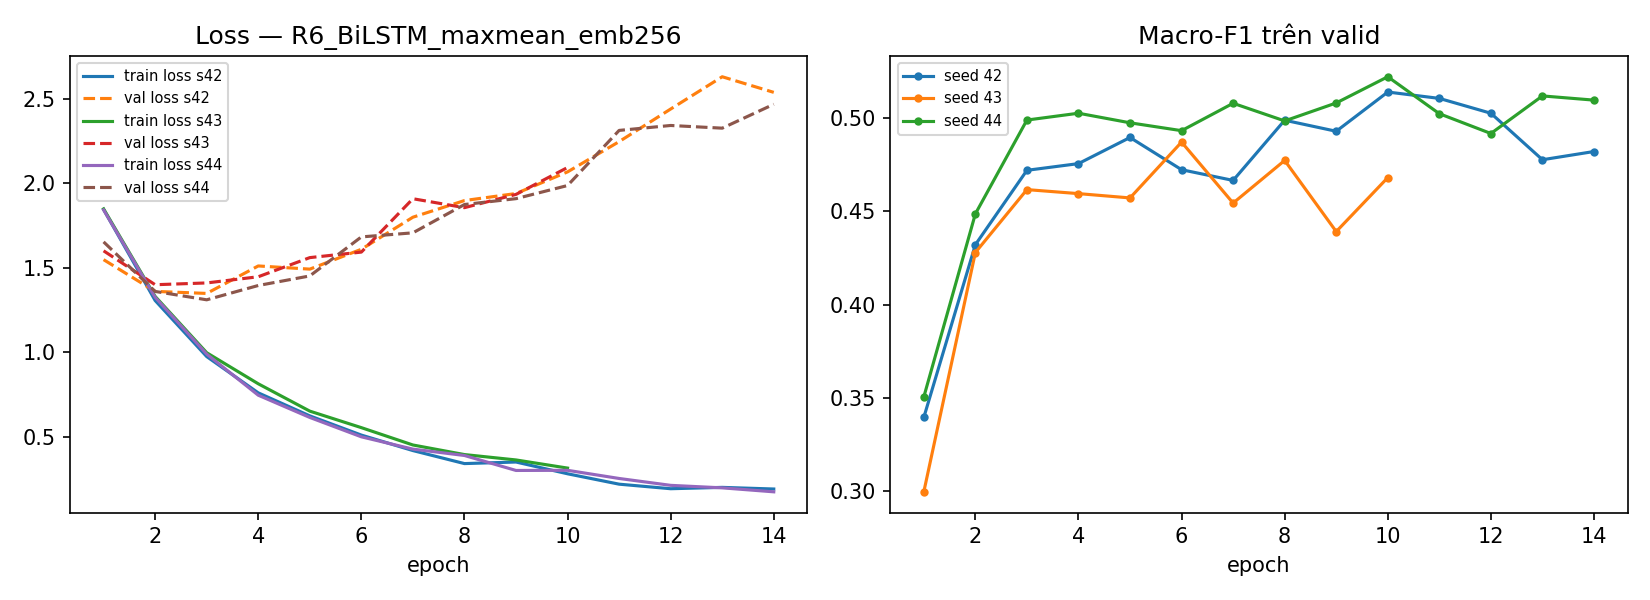

In [10]:
t = pd.read_csv("results/tables/ablation_rnn.csv")
display(t.round(4))
display(Image("results/figures/ablation_rnn.png"))
display(Image("results/figures/rnn_learning_curve.png"))

## 6. Kết quả trên tập test (bảng so sánh chính)

,model,preprocess,feature,val_macro_f1,test_macro_f1,test_macro_f1_std,test_macro_precision,test_macro_recall,test_weighted_f1,test_accuracy
0,Majority class (tham chiếu),-,-,0.0679,0.0622,NaN,0.0398,0.1429,0.1213,0.2785
1,TF-IDF+MultinomialNB,P2_+teencode,word_1-2+char_2-5,0.5403,0.5290,NaN,0.5390,0.5259,0.5631,0.5628
2,TF-IDF+LogReg,P2_+teencode,word_1-2,0.5693,0.5902,NaN,0.6024,0.5830,0.6113,0.6118
3,TF-IDF+LinearSVC,P2_+teencode,word_1-2+char_2-5,0.5619,0.5827,NaN,0.5916,0.5770,0.6014,0.6032
4,R1_LSTM_last,P2_+teencode,embedding học từ đầu,0.4863,0.5173,0.0058,0.5076,0.5352,0.5399,0.5402
5,R6_BiLSTM_maxmean_emb256,P2_+teencode,embedding học từ đầu,0.5077,0.5115,0.0243,0.5002,0.5384,0.5307,0.5291


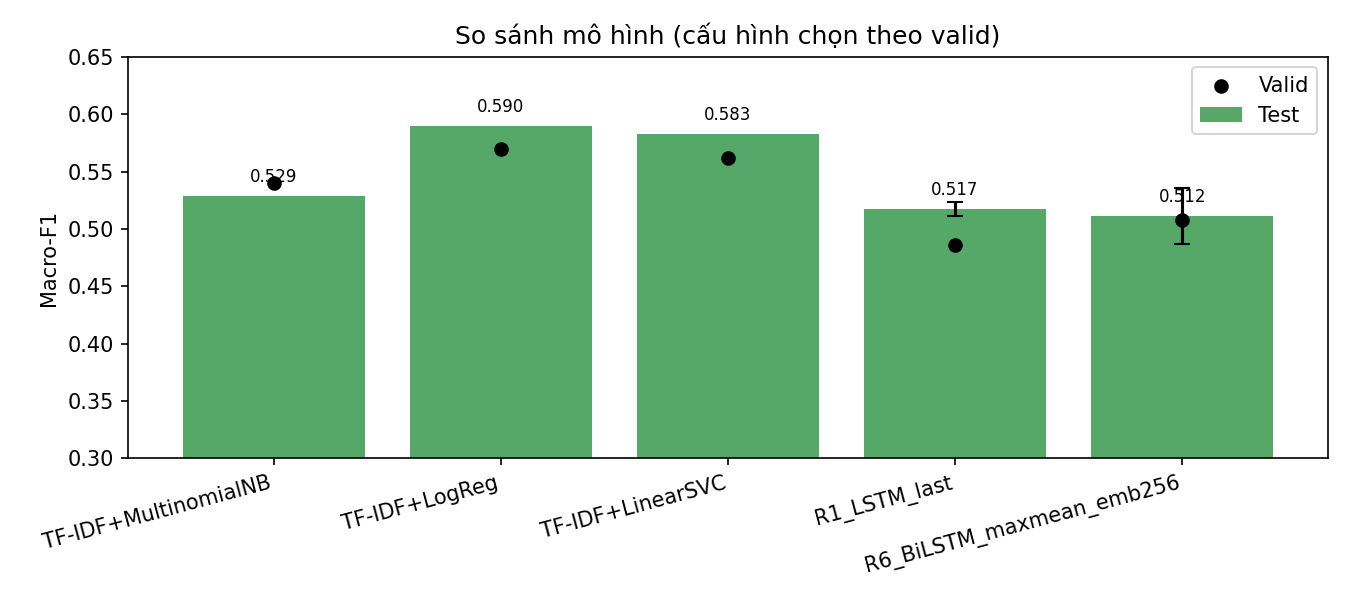

,mean_diff,ci95_low,ci95_high,p_B_not_better,A,B
0,0.0618,0.0214,0.1020,0.002,TF-IDF+MultinomialNB,TF-IDF+LogReg
1,-0.0690,-0.1071,-0.0281,1.000,TF-IDF+LogReg,R6_BiLSTM_maxmean_emb256 (seed 42)


In [11]:
f = pd.read_csv("results/tables/final_comparison_test.csv")
cols = [c for c in ["model", "preprocess", "feature", "val_macro_f1", "test_macro_f1", "test_macro_f1_std",
                    "test_macro_precision", "test_macro_recall", "test_weighted_f1", "test_accuracy"] if c in f]
display(f[cols].round(4))
display(Image("results/figures/final_comparison.png"))
display(pd.read_csv("results/tables/bootstrap_test.csv").round(4))

model,R6_BiLSTM_maxmean_emb256,TF-IDF+LogReg,TF-IDF+MultinomialNB
label,,,
Enjoyment,0.637,0.690,0.675
Sadness,0.623,0.696,0.658
Anger,0.333,0.442,0.368
Fear,0.667,0.682,0.596
Disgust,0.487,0.557,0.521
Surprise,0.505,0.545,0.452
Other,0.398,0.519,0.434


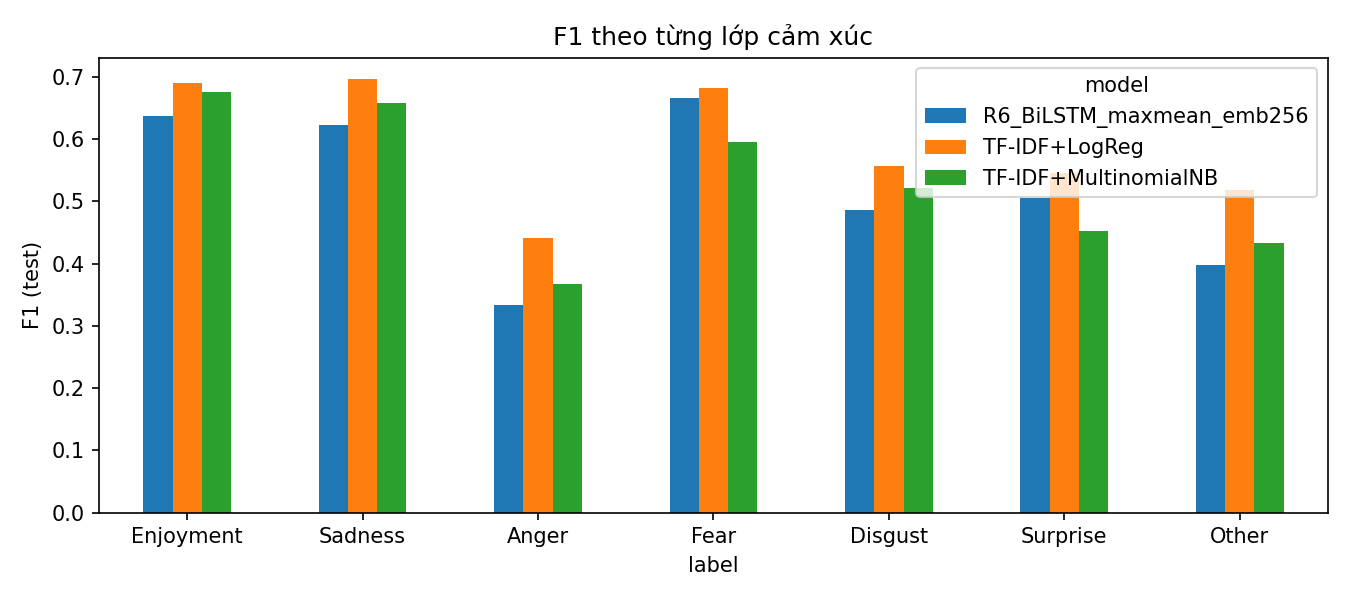

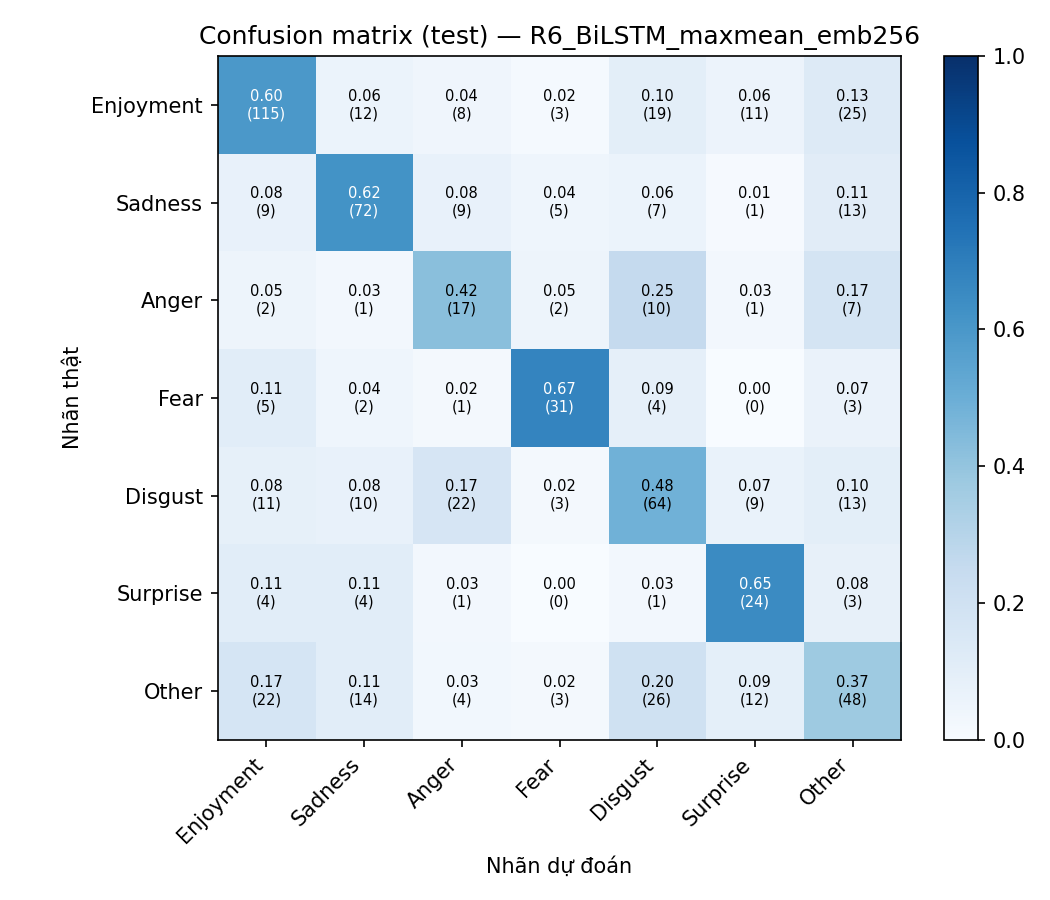

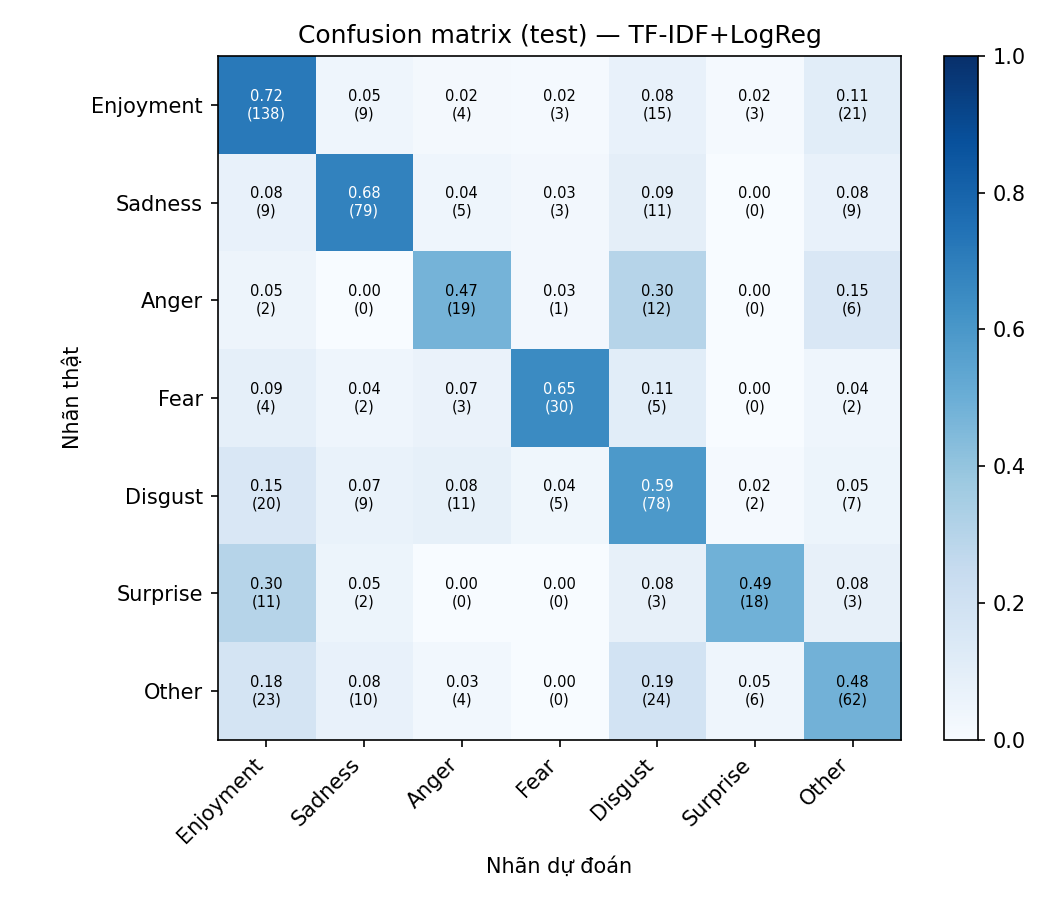

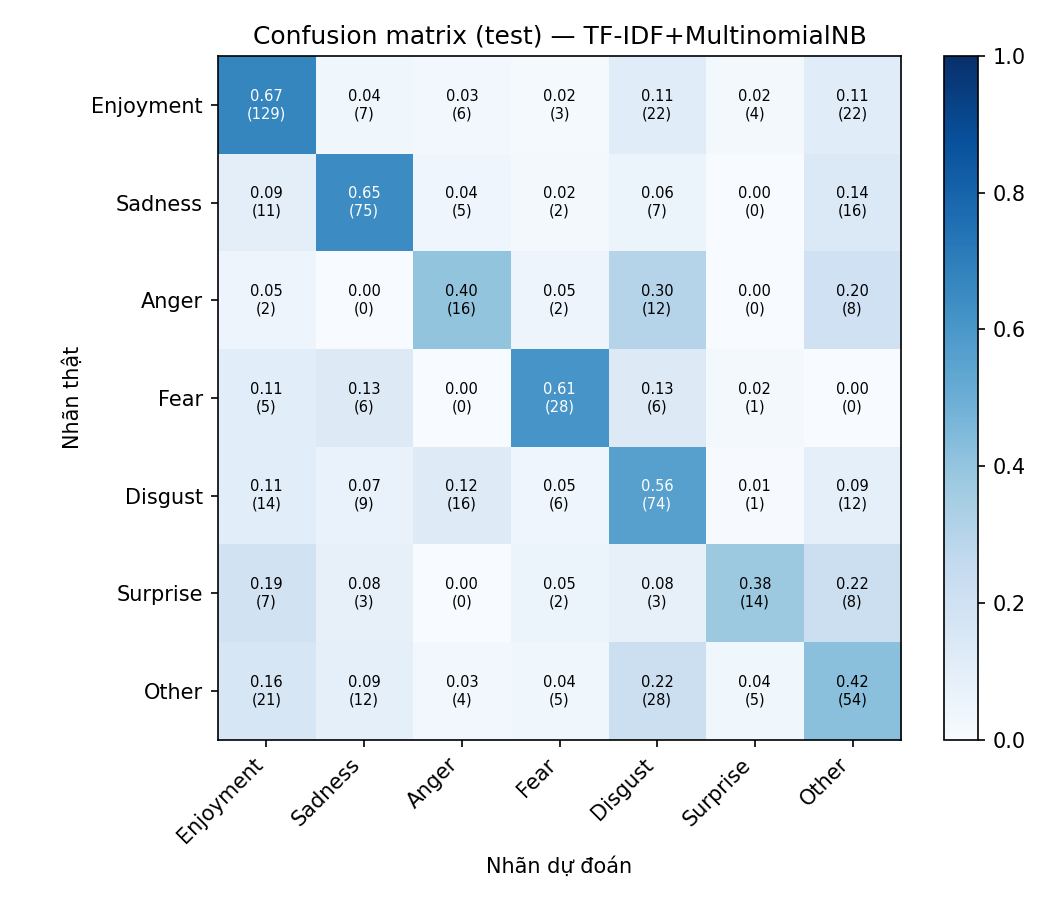

In [12]:
pc = pd.read_csv("results/tables/per_class_test.csv")
display(pc.pivot(index="label", columns="model", values="f1-score").reindex(LABELS).round(3))
display(Image("results/figures/per_class_f1.png"))
import glob
for p in sorted(glob.glob("results/figures/confusion_*.png")):
    display(Image(p))

## 7. Phân tích lỗi

In [13]:
for p in sorted(glob.glob("results/tables/error_top_confusions_*.csv")):
    display(pd.read_csv(p))
display(pd.read_csv("results/tables/error_agreement.csv"))
display(pd.read_csv("results/tables/error_by_length.csv").round(3))
pd.read_csv("results/tables/error_examples.csv", index_col=0)

,model,true,pred,count
0,R6_BiLSTM_maxmean_emb256,Other,Disgust,26
1,R6_BiLSTM_maxmean_emb256,Enjoyment,Other,25
2,R6_BiLSTM_maxmean_emb256,Disgust,Anger,22
3,R6_BiLSTM_maxmean_emb256,Other,Enjoyment,22
4,R6_BiLSTM_maxmean_emb256,Enjoyment,Disgust,19
5,R6_BiLSTM_maxmean_emb256,Other,Sadness,14
6,R6_BiLSTM_maxmean_emb256,Sadness,Other,13
7,R6_BiLSTM_maxmean_emb256,Disgust,Other,13
8,R6_BiLSTM_maxmean_emb256,Other,Surprise,12
9,R6_BiLSTM_maxmean_emb256,Enjoyment,Sadness,12


,model,true,pred,count
0,TF-IDF+LogReg,Other,Disgust,24
1,TF-IDF+LogReg,Other,Enjoyment,23
2,TF-IDF+LogReg,Enjoyment,Other,21
3,TF-IDF+LogReg,Disgust,Enjoyment,20
4,TF-IDF+LogReg,Enjoyment,Disgust,15
5,TF-IDF+LogReg,Anger,Disgust,12
6,TF-IDF+LogReg,Surprise,Enjoyment,11
7,TF-IDF+LogReg,Sadness,Disgust,11
8,TF-IDF+LogReg,Disgust,Anger,11
9,TF-IDF+LogReg,Other,Sadness,10


,TF-IDF+LogReg đúng,False,True
0,False,211,58
1,True,111,313


,len_bin,n,acc_TF-IDF+LogReg,acc_R6_BiLSTM_maxmean_emb256
0,1-5,98,0.735,0.602
1,6-10,208,0.625,0.577
2,11-20,249,0.550,0.490
3,21-40,126,0.611,0.500
4,>40,12,0.667,0.583


,text,true,pred_TF-IDF+LogReg,pred_R6_BiLSTM_maxmean_emb256,conf_R6_BiLSTM_maxmean_emb256,case
15,ổng quay thiệt mà sao chửi ổng thế . không quay sao máy bạn xem được đó :)),Other,Surprise,Surprise,1.000,cả hai sai
195,đám người lớn văn hóa lùn đẻ ra một đám trẻ vô học . bọn mất dạy này là nhà dột từ nóc ấy mà . nên đuổi học cho lũ n...,Anger,Disgust,Disgust,1.000,cả hai sai
137,liên quan gì tới mày . mời đám cưới chắc gì mày đã đi . hỏi hỏi con cặc,Disgust,Anger,Anger,1.000,cả hai sai
252,cái câu liếm củi chỏ sao sai được nhỉ,Other,Surprise,Surprise,1.000,cả hai sai
257,đôi khi thích nói chuyện chỉ vì nói chuyện hợp và vì thích nói chuyện chứ thật ra chả phải yêu đương hay thích kiểu ...,Other,Enjoyment,Enjoyment,0.999,cả hai sai
458,"cũng nhờ thầy khắt khe uốn nén bỏ thói hư tật xấu , bây giờ mỗi lần họp lớp đều nhắc tới thầy và vô cùng kính trọng",Enjoyment,Disgust,Disgust,0.999,cả hai sai
406,tiền mất tật mang . xe đã nát rồi giờ còn phải đền cách cửa cho tàu nửa,Sadness,Disgust,Disgust,0.999,cả hai sai
666,đụ mẹ ngu à :)) có thiếu chỗ đéo nào cho mày viết khôg,Disgust,Anger,Anger,0.999,cả hai sai
21,hậu duệ mặt trời đấy chứ đùa đâu nhá 😗😗,Other,Enjoyment,Other,0.700,chỉ TF-IDF+LogReg sai
31,kêu gọi thì lói thế thôi chứ dân nó vẫn dùng apple như thường,Other,Disgust,Other,0.730,chỉ TF-IDF+LogReg sai


**Diễn giải chính** (chi tiết ở Mục 5.7 của báo cáo `report/NLP_BTL_MaNhom.pdf`):
- *Anger ↔ Disgust*: câu chửi bới có ranh giới nhãn mờ; từ tục xuất hiện ở cả hai lớp.
- *Câu hỏi tu từ → Surprise*: "sao", ":))", "nhỉ" là từ khóa của Surprise nhưng câu thực chất là phản bác (Other).
- *Từ tiêu cực trong câu tích cực / thành ngữ*: "khắt khe... bỏ thói hư tật xấu" (biết ơn) bị đoán Disgust.
- *Other* không có từ khóa riêng nên bị kéo sang lớp có cảm xúc.
- *BiLSTM quá tự tin* (xác suất ≈ 1 khi sai), dấu hiệu quá khớp, nên ensemble không có lợi.

## 8. Demo

In [14]:
from demo import Predictor, show
p = Predictor()
for s in ["sản phẩm dùng được 2 hôm đã hỏng, phí tiền vãi",
          "hàng về đẹp quá, shop đóng gói cẩn thận 😍",
          "trời ơi giao hàng nhanh không tưởng luôn á",
          "nhìn con gián trong hộp mà sợ muốn chết"]:
    show(p, s)


Câu: sản phẩm dùng được 2 hôm đã hỏng, phí tiền vãi


  [TF-IDF+LogReg] -> Surprise (Ngạc nhiên)   | đã tiền xử lý: sản phẩm dùng được num hôm đã hỏng , phí tiền vãi
     top-3: Surprise 0.37, Disgust 0.36, Enjoyment 0.15
  [R6_BiLSTM_maxmean_emb256] -> Surprise (Ngạc nhiên)   | đã tiền xử lý: sản phẩm dùng được num hôm đã hỏng , phí tiền vãi
     top-3: Surprise 0.99, Other 0.01, Enjoyment 0.00

Câu: hàng về đẹp quá, shop đóng gói cẩn thận 😍
  [TF-IDF+LogReg] -> Enjoyment (Vui thích)   | đã tiền xử lý: hàng về đẹp quá , shop đóng gói cẩn thận 😍
     top-3: Enjoyment 0.87, Other 0.04, Fear 0.04
  [R6_BiLSTM_maxmean_emb256] -> Enjoyment (Vui thích)   | đã tiền xử lý: hàng về đẹp quá , shop đóng gói cẩn thận 😍
     top-3: Enjoyment 0.99, Other 0.00, Disgust 0.00

Câu: trời ơi giao hàng nhanh không tưởng luôn á
  [TF-IDF+LogReg] -> Surprise (Ngạc nhiên)   | đã tiền xử lý: trời ơi giao hàng nhanh không tưởng luôn á
     top-3: Surprise 0.75, Enjoyment 0.08, Disgust 0.08
  [R6_BiLSTM_maxmean_emb256] -> Surprise (Ngạc nhiên)   | đã tiền xử lý: 

  [TF-IDF+LogReg] -> Fear (Sợ hãi)   | đã tiền xử lý: nhìn con gián trong hộp mà sợ muốn chết
     top-3: Fear 0.94, Anger 0.02, Other 0.01
  [R6_BiLSTM_maxmean_emb256] -> Fear (Sợ hãi)   | đã tiền xử lý: nhìn con gián trong hộp mà sợ muốn chết
     top-3: Fear 0.99, Other 0.00, Sadness 0.00
